**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits
from src.representation import fit_pca, pca_project, load_autoencoder, ae_encode, compute_hog
from src.retrieval import SearchSpace, retrieve

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
pca = fit_pca(X_train)

**Célula 2 – construir os três espaços (galeria = treino):**

In [2]:
d = 32                                            
ae = load_autoencoder(d, f"models/ae_{d}.pt")

start = time.perf_counter()
spaces = [
    SearchSpace(f"shape (PCA-{d})", lambda X: pca_project(pca, X, d), X_train),
    SearchSpace("texture/edges (HOG)", compute_hog, X_train),
    SearchSpace(f"learned (AE-{d})", lambda X: ae_encode(ae, X), X_train),
]
print(f"Galerias construídas em {time.perf_counter() - start:.1f} s")
for s in spaces:
    print(f"{s.name:22s} -> galeria {s.gallery_features.shape}")

Galerias construídas em 11.1 s
shape (PCA-32)         -> galeria (50000, 32)
texture/edges (HOG)    -> galeria (50000, 324)
learned (AE-32)        -> galeria (50000, 32)


**Célula 3 – testar com uma query:**

In [ ]:
q = 0                                              
results = retrieve(X_test[q], spaces, k=5)

print("Query: imagem de teste", q, "| classe real:", CLASS_NAMES[y_test[q]])  
for name, (idx, dist) in results.items():
    print(f"\n{name}")
    print("  índices na galeria:", idx[0])
    print("  distâncias:        ", np.round(dist[0], 3))
    print("  classes (só p/ avaliar):", [CLASS_NAMES[y_train[i]] for i in idx[0]])

Query: imagem de teste 0 | classe real: Ankle boot

shape (PCA-32)
  índices na galeria: [  977  9975  4882 16532 25108]
  distâncias:         [0.922 1.101 1.176 1.364 1.486]
  classes (só p/ avaliar): ['Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot']

texture/edges (HOG)
  índices na galeria: [  977   649 15736  6351 45366]
  distâncias:         [1.022 1.142 1.2   1.227 1.263]
  classes (só p/ avaliar): ['Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot']

learned (AE-32)
  índices na galeria: [  977 16532 40436 28567  4881]
  distâncias:         [2.056 2.588 2.596 2.758 2.841]
  classes (só p/ avaliar): ['Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot', 'Ankle boot']


**Célula 4 – mini-painel de verificação:**

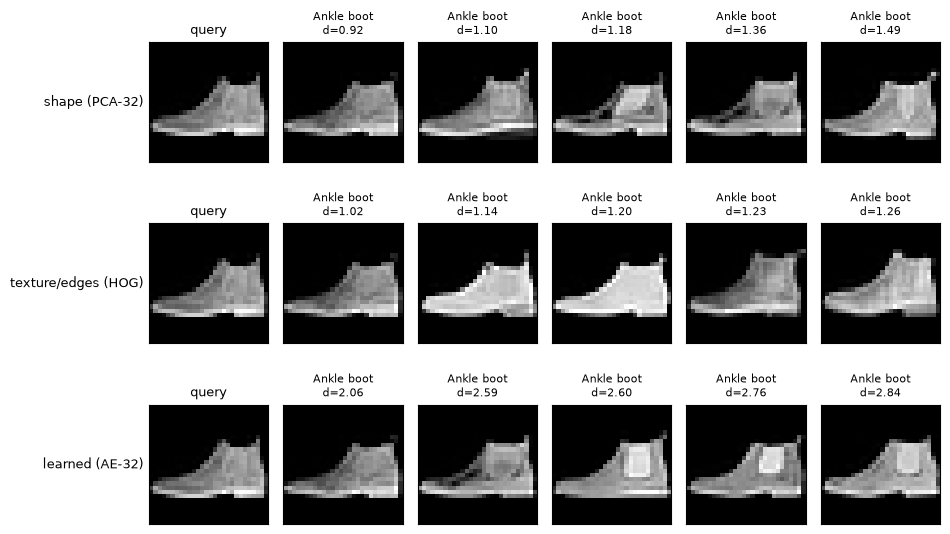

In [ ]:
k = 5
fig, axes = plt.subplots(len(spaces), k + 1, figsize=((k + 1) * 1.6, len(spaces) * 1.9))
for r, (name, (idx, dist)) in enumerate(results.items()):
    axes[r, 0].imshow(X_test[q].reshape(28, 28), cmap="gray")
    axes[r, 0].set_title("query", fontsize=9)
    axes[r, 0].set_ylabel(name, fontsize=9, rotation=0, ha="right", va="center")
    for j in range(k):
        i = idx[0, j]
        axes[r, j + 1].imshow(X_train[i].reshape(28, 28), cmap="gray")
        axes[r, j + 1].set_title(f"{CLASS_NAMES[y_train[i]]}\nd={dist[0, j]:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()